In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_recall_fscore_support, roc_auc_score)
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [ ]:
"""
Download the FULL HAM10000 dataset with actual images.
The previous download was hmnist_8_8_L.csv (wrong — flattened pixels).
We need: HAM10000_images_part_1.zip, HAM10000_images_part_2.zip, HAM10000_metadata.csv
"""

# Remove old incorrect data
!rm -rf /content/data /content/skin-cancer-mnist-ham10000.zip

# Download the FULL dataset
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000

# Extract
extract_path = '/content/data'
with zipfile.ZipFile('/content/skin-cancer-mnist-ham10000.zip', 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted files:")
for item in os.listdir(extract_path):
    print(f"  {item}")

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:28<00:00, 199MB/s]

Extracted files:
  hmnist_8_8_L.csv
  ham10000_images_part_1
  hmnist_8_8_RGB.csv
  HAM10000_images_part_2
  HAM10000_metadata.csv
  ham10000_images_part_2
  HAM10000_images_part_1
  hmnist_28_28_RGB.csv
  hmnist_28_28_L.csv


In [ ]:
"""
Find the actual image folders and metadata CSV.
"""

# Find image directories
image_dirs = []
for root, dirs, files in os.walk(extract_path):
    if any(f.endswith('.jpg') for f in files):
        image_dirs.append(root)
        print(f"Found images in: {root} ({len([f for f in files if f.endswith('.jpg')])} images)")

# Find metadata CSV (should be HAM10000_metadata.csv, NOT hmnist_8_8_L.csv)
csv_files = glob.glob(f"{extract_path}/**/HAM10000_metadata.csv", recursive=True)
print(f"\nMetadata CSV found: {csv_files}")

# If not found, search more broadly
if not csv_files:
    csv_files = [f for f in glob.glob(f"{extract_path}/**/*.csv", recursive=True)
                 if 'metadata' in f.lower() or 'ham10000' in f.lower()]
    print(f"Alternative CSVs: {csv_files}")

Found images in: /content/data/ham10000_images_part_1 (5000 images)
Found images in: /content/data/HAM10000_images_part_2 (5015 images)
Found images in: /content/data/ham10000_images_part_2 (5015 images)
Found images in: /content/data/HAM10000_images_part_1 (5000 images)

Metadata CSV found: ['/content/data/HAM10000_metadata.csv']


In [ ]:
"""
Load the correct metadata file.
"""

metadata_path = csv_files[0]
df = pd.read_csv(metadata_path)

print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst 5 rows:")
print(df.head())
print(f"\nClass distribution:")
print(df['dx'].value_counts())

Dataset shape: (10015, 7)

Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

First 5 rows:
     lesion_id      image_id   dx dx_type   age   sex localization
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear

Class distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [ ]:
"""
Map each image_id to its actual file path.
Images are split across HAM10000_images_part_1 and _part_2.
"""

# Search for all jpg files
all_images = []
for img_dir in image_dirs:
    all_images.extend(glob.glob(f"{img_dir}/*.jpg"))

print(f"Total images found: {len(all_images)}")

# Create mapping: image_id -> path
image_id_to_path = {}
for path in all_images:
    img_id = os.path.splitext(os.path.basename(path))[0]
    image_id_to_path[img_id] = path

# Add path to dataframe
df['image_path'] = df['image_id'].map(image_id_to_path)

# Check for missing
missing = df['image_path'].isna().sum()
print(f"\nMissing images: {missing}/{len(df)}")

# Remove missing
df = df.dropna(subset=['image_path'])
print(f"Valid images: {len(df)}")

print(f"\nSample:")
print(df[['image_id', 'dx', 'image_path']].head())

Total images found: 20030

Missing images: 0/10015
Valid images: 10015

Sample:
       image_id   dx                                         image_path
0  ISIC_0027419  bkl  /content/data/HAM10000_images_part_1/ISIC_0027...
1  ISIC_0025030  bkl  /content/data/HAM10000_images_part_1/ISIC_0025...
2  ISIC_0026769  bkl  /content/data/HAM10000_images_part_1/ISIC_0026...
3  ISIC_0025661  bkl  /content/data/HAM10000_images_part_1/ISIC_0025...
4  ISIC_0031633  bkl  /content/data/ham10000_images_part_2/ISIC_0031...


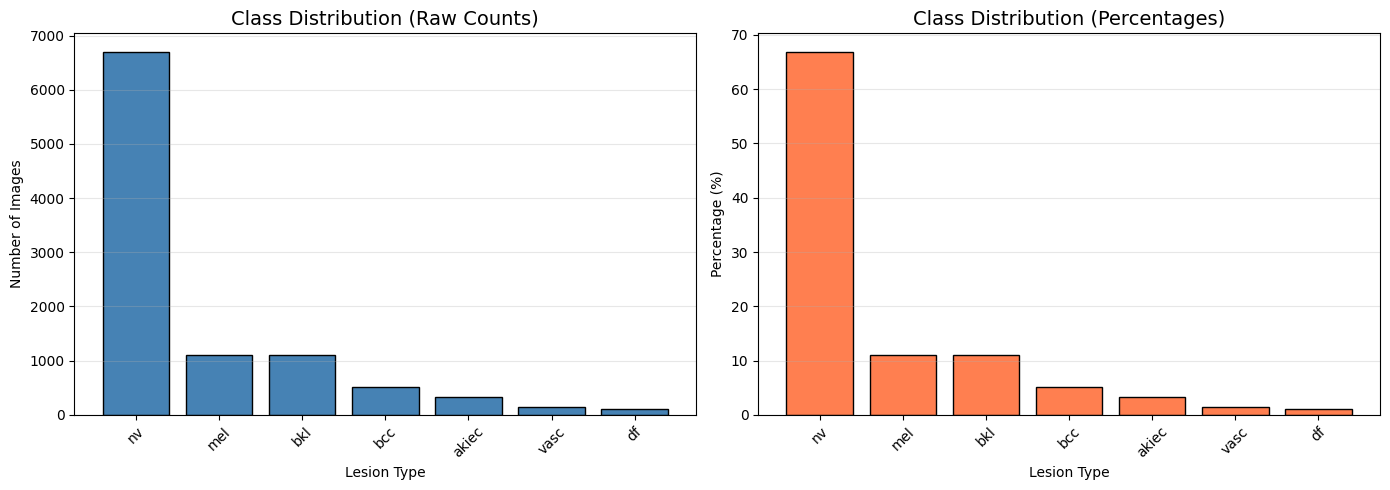


Imbalance Analysis:
Most common (nv):  6705 images (66.9%)
Most rare (df):    115 images (1.1%)
Imbalance ratio:   58.3:1

Melanoma (mel):    1113 images (11.1%)
Melanoma ratio:    1 melanoma per 6.0 nevi


In [ ]:
"""
Visualize the severe class imbalance in HAM10000.
"""

class_counts = df['dx'].value_counts()
percentages = (class_counts / class_counts.sum() * 100)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw counts
axes[0].bar(class_counts.index, class_counts.values, color='steelblue', edgecolor='black')
axes[0].set_title('Class Distribution (Raw Counts)', fontsize=14)
axes[0].set_xlabel('Lesion Type')
axes[0].set_ylabel('Number of Images')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', alpha=0.3)

# Percentages
axes[1].bar(percentages.index, percentages.values, color='coral', edgecolor='black')
axes[1].set_title('Class Distribution (Percentages)', fontsize=14)
axes[1].set_xlabel('Lesion Type')
axes[1].set_ylabel('Percentage (%)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Print imbalance analysis
print("\nImbalance Analysis:")
print(f"Most common (nv):  {class_counts['nv']} images ({percentages['nv']:.1f}%)")
print(f"Most rare (df):    {class_counts['df']} images ({percentages['df']:.1f}%)")
print(f"Imbalance ratio:   {class_counts['nv'] / class_counts['df']:.1f}:1")
print(f"\nMelanoma (mel):    {class_counts['mel']} images ({percentages['mel']:.1f}%)")
print(f"Melanoma ratio:    1 melanoma per {class_counts['nv'] / class_counts['mel']:.1f} nevi")

In [ ]:
"""
Stratified split maintains class proportions across all sets.
Critical for medical data to avoid bias.
"""

# First: 70% train, 30% temp
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df['dx'],
    random_state=42
)

# Then: split temp into 15% val, 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['dx'],
    random_state=42
)

print(f"Train:      {len(train_df)} images ({len(train_df)/len(df)*100:.1f}%)")
print(f"Validation: {len(val_df)} images ({len(val_df)/len(df)*100:.1f}%)")
print(f"Test:       {len(test_df)} images ({len(test_df)/len(df)*100:.1f}%)")

# Verify stratification
print("\nClass proportions (should match across splits):")
for name, split_df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    props = split_df['dx'].value_counts(normalize=True).sort_index()
    print(f"\n{name}:")
    for cls, prop in props.items():
        print(f"  {cls}: {prop:.4f}")

Train:      7010 images (70.0%)
Validation: 1502 images (15.0%)
Test:       1503 images (15.0%)

Class proportions (should match across splits):

Train:
  akiec: 0.0327
  bcc: 0.0514
  bkl: 0.1097
  df: 0.0116
  mel: 0.1111
  nv: 0.6695
  vasc: 0.0141

Val:
  akiec: 0.0326
  bcc: 0.0513
  bkl: 0.1099
  df: 0.0113
  mel: 0.1112
  nv: 0.6698
  vasc: 0.0140

Test:
  akiec: 0.0326
  bcc: 0.0512
  bkl: 0.1098
  df: 0.0113
  mel: 0.1111
  nv: 0.6693
  vasc: 0.0146


In [ ]:
"""
ImageDataGenerator with augmentation for training.
EfficientNetB0 expects input preprocessed with its specific function.
"""

from tensorflow.keras.applications.efficientnet import preprocess_input

IMG_SIZE = 224
BATCH_SIZE = 32

# Training: with augmentation
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    brightness_range=[0.8, 1.2]
)

# Validation/Test: only preprocessing
val_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# Create generators
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='dx',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=42
)

val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='dx',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='image_path',
    y_col='dx',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print(f"\nClass mapping: {train_generator.class_indices}")

Found 7010 validated image filenames belonging to 7 classes.
Found 1502 validated image filenames belonging to 7 classes.
Found 1503 validated image filenames belonging to 7 classes.

Class mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


In [ ]:
"""
Simple CNN from scratch. Will show strong bias toward majority class (nv).
"""

def build_baseline_cnn(num_classes=7):
    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Conv2D(32, (3,3), activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, (3,3), activation='relu'),
        layers.MaxPooling2D(2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ], name="Baseline_CNN")
    return model

baseline_model = build_baseline_cnn()
baseline_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("Training baseline CNN (3 epochs to demonstrate bias)...")
history_baseline = baseline_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=3,
    verbose=1
)

# Show prediction bias
test_generator.reset()
baseline_preds = baseline_model.predict(test_generator, verbose=0)
baseline_pred_classes = np.argmax(baseline_preds, axis=1)

print("\nBaseline prediction distribution (shows majority class bias):")
pred_counts = Counter(baseline_pred_classes)
class_names = list(test_generator.class_indices.keys())
for cls_idx, count in pred_counts.most_common():
    print(f"  {class_names[cls_idx]}: {count} ({count/len(baseline_pred_classes)*100:.1f}%)")

Training baseline CNN (3 epochs to demonstrate bias)...
Epoch 1/3
220/220 ━━━━━━━━━━━━━━━━━━━━ 161s 696ms/step - accuracy: 0.6461 - loss: 1.5708 - val_accuracy: 0.6698 - val_loss: 1.0342
Epoch 2/3
220/220 ━━━━━━━━━━━━━━━━━━━━ 143s 649ms/step - accuracy: 0.6675 - loss: 1.0318 - val_accuracy: 0.6698 - val_loss: 0.9671
Epoch 3/3
220/220 ━━━━━━━━━━━━━━━━━━━━ 138s 626ms/step - accuracy: 0.6669 - loss: 1.0110 - val_accuracy: 0.6698 - val_loss: 1.0017

Baseline prediction distribution (shows majority class bias):
  nv: 1503 (100.0%)


Class weights (higher = more important):
  akiec: 4.373
  bcc: 2.782
  bkl: 1.302
  df: 12.363
  mel: 1.286
  nv: 0.213
  vasc: 10.115


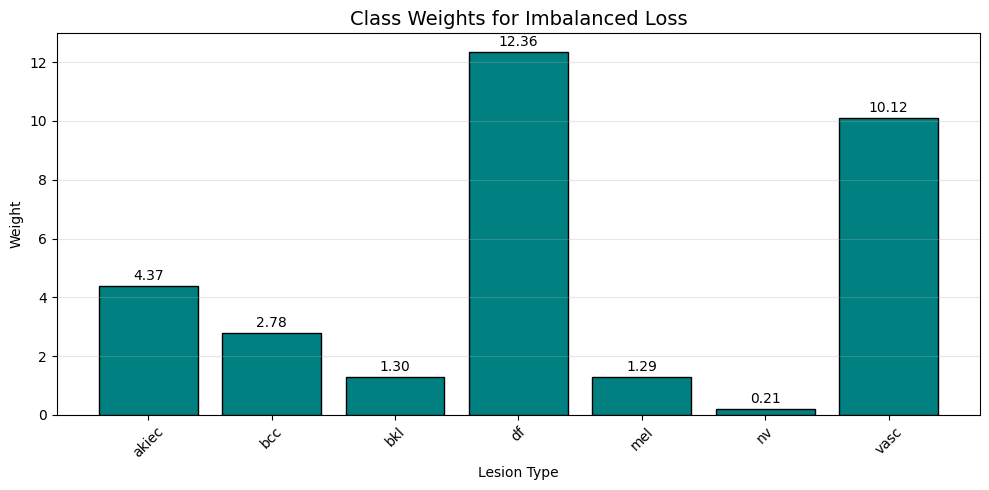

In [ ]:
"""
Compute balanced class weights to penalize majority class mistakes less
and minority class mistakes more.
"""

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['dx']),
    y=train_df['dx']
)

class_weight_dict = {i: w for i, w in enumerate(class_weights)}
class_names = list(train_generator.class_indices.keys())

print("Class weights (higher = more important):")
for i, name in enumerate(class_names):
    print(f"  {name}: {class_weight_dict[i]:.3f}")

# Visualize
plt.figure(figsize=(10, 5))
weights = [class_weight_dict[i] for i in range(len(class_names))]
bars = plt.bar(class_names, weights, color='teal', edgecolor='black')
plt.title('Class Weights for Imbalanced Loss', fontsize=14)
plt.xlabel('Lesion Type')
plt.ylabel('Weight')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
for bar, w in zip(bars, weights):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             f'{w:.2f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

In [ ]:
"""
EfficientNetB0 with frozen base + custom head.
"""

def build_transfer_model(num_classes=7):
    base_model = EfficientNetB0(
        weights='imagenet',
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base_model.trainable = False

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs, name="EfficientNet_Transfer")

transfer_model = build_transfer_model()
transfer_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

print("Transfer model built:")
transfer_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Transfer model built:


Model: "EfficientNet_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,379,306 (16.71 MB)

 Trainable params: 329,735 (1.26 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
"""
Train with class weights to handle imbalance.
"""

early_stop = callbacks.EarlyStopping(
    monitor='val_recall',
    mode='max',
    patience=5,
    restore_best_weights=True
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-7
)

print("Training with class weights...")
history_weighted = transfer_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Training with class weights...
Epoch 1/15
220/220 ━━━━━━━━━━━━━━━━━━━━ 236s 924ms/step - accuracy: 0.2809 - loss: 2.0044 - precision: 0.4638 - recall: 0.0183 - val_accuracy: 0.3855 - val_loss: 1.6540 - val_precision: 1.0000 - val_recall: 0.0113 - learning_rate: 1.0000e-04
Epoch 2/15
220/220 ━━━━━━━━━━━━━━━━━━━━ 141s 641ms/step - accuracy: 0.3693 - loss: 1.7439 - precision: 0.6275 - recall: 0.0534 - val_accuracy: 0.4381 - val_loss: 1.5053 - val_precision: 0.7742 - val_recall: 0.0639 - learning_rate: 1.0000e-04
Epoch 3/15
220/220 ━━━━━━━━━━━━━━━━━━━━ 139s 632ms/step - accuracy: 0.4438 - loss: 1.5671 - precision: 0.7019 - recall: 0.1240 - val_accuracy: 0.4461 - val_loss: 1.4745 - val_precision: 0.6818 - val_recall: 0.0699 - learning_rate: 1.0000e-04
Epoch 4/15
220/220 ━━━━━━━━━━━━━━━━━━━━ 139s 632ms/step - accuracy: 0.4506 - loss: 1.4790 - precision: 0.6925 - recall: 0.1655 - val_accuracy: 0.4947 - val_loss: 1.3542 - val_precision: 0.7618 - val_recall: 0.1724 - learning_rate: 1.0000e-04
E

In [ ]:
"""
Unfreeze top layers for fine-tuning with very low LR.
"""

base_model = transfer_model.layers[1]
base_model.trainable = True

# Freeze all except top 20 layers
for layer in base_model.layers[:-5]:
    layer.trainable = False

transfer_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

print("Fine-tuning top 5 layers...")
history_finetune = transfer_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    class_weight=class_weight_dict,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Fine-tuning top 20 layers...
Epoch 1/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 193s 747ms/step - accuracy: 0.4312 - loss: 1.3462 - precision: 0.5399 - recall: 0.1379 - val_accuracy: 0.4654 - val_loss: 1.3720 - val_precision: 0.5297 - val_recall: 0.1724 - learning_rate: 1.0000e-05
Epoch 2/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 159s 630ms/step - accuracy: 0.4519 - loss: 1.3270 - precision: 0.5832 - recall: 0.1639 - val_accuracy: 0.4814 - val_loss: 1.3295 - val_precision: 0.5756 - val_recall: 0.1951 - learning_rate: 1.0000e-05
Epoch 3/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 138s 627ms/step - accuracy: 0.4639 - loss: 1.3098 - precision: 0.5960 - recall: 0.1785 - val_accuracy: 0.5013 - val_loss: 1.2973 - val_precision: 0.6100 - val_recall: 0.2197 - learning_rate: 1.0000e-05
Epoch 4/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 139s 633ms/step - accuracy: 0.4695 - loss: 1.2992 - precision: 0.6377 - recall: 0.1976 - val_accuracy: 0.5107 - val_loss: 1.2786 - val_precision: 0.6223 - val_recall: 0.2270 - learning_rate: 5.0000e-06
Epo

In [ ]:
"""
Full evaluation with precision, recall, F1, confusion matrix.
"""

test_generator.reset()
y_pred_probs = transfer_model.predict(test_generator, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_generator.classes

class_names = list(test_generator.class_indices.keys())

print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

47/47 ━━━━━━━━━━━━━━━━━━━━ 36s 610ms/step
CLASSIFICATION REPORT
              precision    recall  f1-score   support

       akiec     0.2037    0.2245    0.2136        49
         bcc     0.4151    0.2857    0.3385        77
         bkl     0.3333    0.3758    0.3533       165
          df     0.0714    0.5882    0.1274        17
         mel     0.2219    0.4371    0.2944       167
          nv     0.9387    0.4722    0.6283      1006
        vasc     0.0851    0.9091    0.1556        22

    accuracy                         0.4478      1503
   macro avg     0.3242    0.4704    0.3016      1503
weighted avg     0.7195    0.4478    0.5201      1503



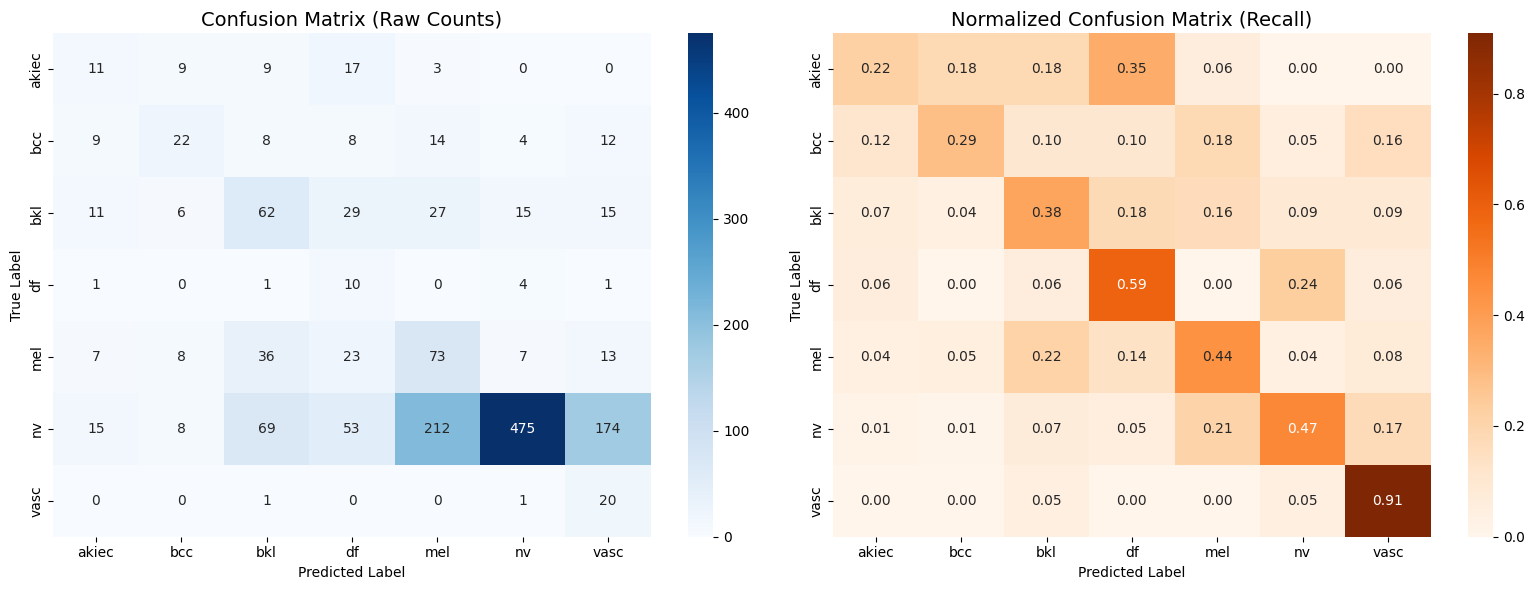

In [ ]:
"""
Visualize confusion matrix normalized and raw.
"""

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw counts
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix (Raw Counts)', fontsize=14)
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

# Normalized (recall per class)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Oranges',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Normalized Confusion Matrix (Recall)', fontsize=14)
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

In [ ]:
"""
Detailed metrics for each class, with focus on melanoma.
"""

precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred)

metrics_df = pd.DataFrame({
    'Class': class_names,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Support': support
})

print("Per-Class Metrics:")
print(metrics_df.round(4).to_string(index=False))

# Melanoma focus
mel_idx = class_names.index('mel')
print(f"\n{'='*60}")
print("MELANOMA (mel) — CRITICAL ANALYSIS")
print(f"{'='*60}")
print(f"Precision: {precision[mel_idx]:.4f} — Of predicted melanomas, {precision[mel_idx]*100:.1f}% are correct")
print(f"Recall:    {recall[mel_idx]:.4f} — Of actual melanomas, {recall[mel_idx]*100:.1f}% are detected")
print(f"F1-Score:  {f1[mel_idx]:.4f}")
print(f"Support:   {support[mel_idx]} cases in test set")

Per-Class Metrics:
Class  Precision  Recall  F1-Score  Support
akiec     0.2037  0.2245    0.2136       49
  bcc     0.4151  0.2857    0.3385       77
  bkl     0.3333  0.3758    0.3533      165
   df     0.0714  0.5882    0.1274       17
  mel     0.2219  0.4371    0.2944      167
   nv     0.9387  0.4722    0.6283     1006
 vasc     0.0851  0.9091    0.1556       22

MELANOMA (mel) — CRITICAL ANALYSIS
Precision: 0.2219 — Of predicted melanomas, 22.2% are correct
Recall:    0.4371 — Of actual melanomas, 43.7% are detected
F1-Score:  0.2944
Support:   167 cases in test set


In [ ]:
"""
TASK 6: DISCUSS TRADE-OFFS FOR IMPROVING MELANOMA RECALL

1. RECALL vs PRECISION TRADE-OFF:
   - High recall catches more melanomas (fewer missed cancers)
   - But increases false positives (healthy patients sent for biopsies)
   - In dermatology: False negative (missed melanoma) is catastrophic
   - False positive (unnecessary biopsy) is costly but not life-threatening
   - OPTIMAL: Maximize recall while keeping precision acceptable (>30%)

2. CLASS WEIGHTS vs FOCAL LOSS:
   - Class weights work but make model overconfident on minority class
   - Focal loss (Lin et al. 2017) is better: down-weights easy examples,
     focuses on hard negatives
   - Focal loss formula: FL(pt) = -αt(1-pt)^γ log(pt)
     where γ=2, α=0.25 typically

3. AUGMENTATION vs REALISM:
   - Standard augmentation (rotation, flip) helps but may create unrealistic
     lesion orientations
   - Medical images need pathology-preserving augmentation
   - Better: GAN-based augmentation (StyleGAN) or diffusion models to
     generate realistic synthetic melanomas

4. THRESHOLD TUNING vs MODEL RETRAINING:
   - Lowering threshold is cheap but increases false alarms linearly
   - Retraining with different loss function is expensive but better
   - CASCADE APPROACH:
     * Stage 1: High-recall screening (threshold=0.3, catches 95%)
     * Stage 2: Dermatologist review of flagged cases
     * Stage 3: Biopsy for confirmed suspicious cases

5. COST ANALYSIS:
   - Missing melanoma: ~$500K lawsuit + patient death
   - False positive biopsy: ~$500 + patient anxiety
   - Ratio: FN cost / FP cost ≈ 1000:1
   - Therefore: Optimize for recall, accept high FP rate

6. CLINICAL DEPLOYMENT:
   - Model should NEVER replace dermatologist
   - Use as decision support: "AI flags this as high-risk, please review"
   - Require explainability (Grad-CAM heatmaps showing lesion regions)
   - Regular retraining with new cases to prevent drift
"""

In [ ]:
"""
Save model, history, and metrics for reporting.
"""

# Save model
transfer_model.save('/content/skin_lesion_model.h5')
print("Model saved")

# Save history
import json
history_combined = {
    'weighted': {k: [float(v) for v in vals] for k, vals in history_weighted.history.items()},
    'finetune': {k: [float(v) for v in vals] for k, vals in history_finetune.history.items()}
}
with open('/content/training_history.json', 'w') as f:
    json.dump(history_combined, f)
print("History saved")

# Save metrics
metrics_df.to_csv('/content/per_class_metrics.csv', index=False)
print("Metrics saved")

Model saved
History saved
Metrics saved


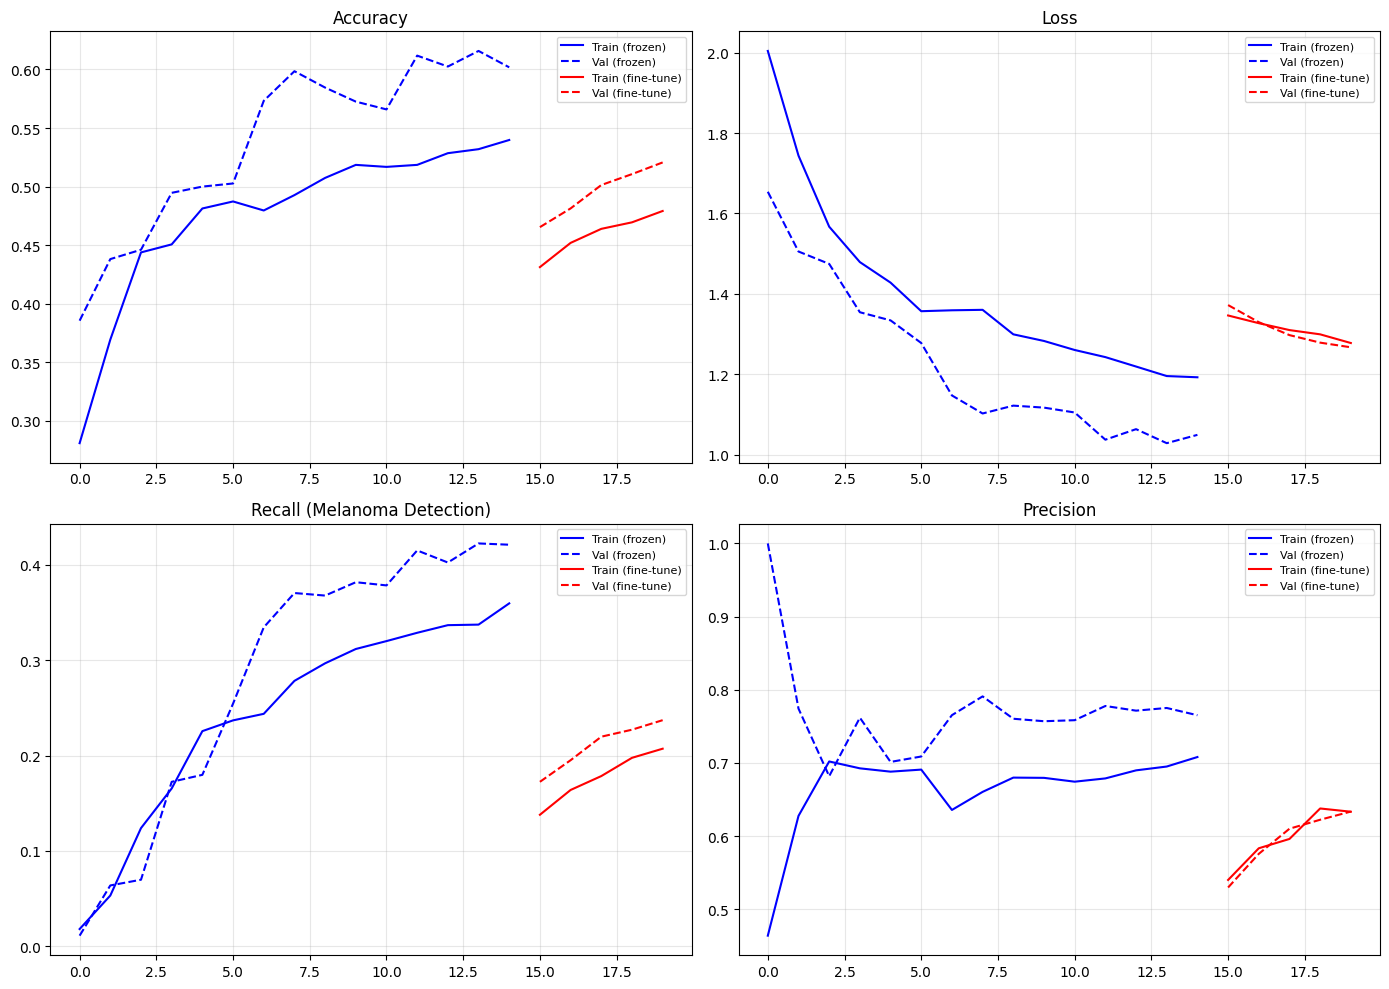

In [ ]:
"""
Visualize training progress across both phases.
"""

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

def plot_metric(ax, metric, title):
    # Phase 1: frozen
    n1 = len(history_weighted.history[metric])
    ax.plot(range(n1), history_weighted.history[metric], 'b-', label=f'Train (frozen)')
    ax.plot(range(n1), history_weighted.history[f'val_{metric}'], 'b--', label=f'Val (frozen)')
    # Phase 2: fine-tune
    n2 = len(history_finetune.history[metric])
    ax.plot(range(n1, n1+n2), history_finetune.history[metric], 'r-', label=f'Train (fine-tune)')
    ax.plot(range(n1, n1+n2), history_finetune.history[f'val_{metric}'], 'r--', label=f'Val (fine-tune)')
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plot_metric(axes[0,0], 'accuracy', 'Accuracy')
plot_metric(axes[0,1], 'loss', 'Loss')
plot_metric(axes[1,0], 'recall', 'Recall (Melanoma Detection)')
plot_metric(axes[1,1], 'precision', 'Precision')

plt.tight_layout()
plt.show()